# 03 — Freight Rate Analysis (Drewry WCI)

Source: Drewry World Container Index (WCI), Shanghai → Rotterdam spot rate (USD/FEU), monthly, Jul 2021 – Aug 2026.

Purpose: Inspect the freight data and produce a processed file for the Monte Carlo model.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## Data collection

Historical WCI data is not freely available as a dataset. The 62 monthly values were collected manually with Claude from Drewry's weekly reports, as republished in free shipping press.

- **Rule:** the first weekly assessment (first Thursday) of each month, applied regardless of the value, to avoid selecting weeks by outcome.
- **Traceability:** every value is stored with its source URL in the raw file.
- **Period:** starts in July 2021 because free weekly coverage before mid-2021 is too sparse to collect reliably.
- **Flags:** values that could not be read directly are marked in the `note` column, either derived exactly from the following week's report or approximated from a rounded percentage change.

In [2]:
raw_url = 'https://github.com/Isakstevik/shipping-route-monte-carlo-V1/raw/refs/heads/main/data/raw/wci_shanghai_rotterdam_monthly.csv'

wci_df = pd.read_csv(raw_url)
wci_df.head()

,month,assessment_date,wci_shanghai_rotterdam_usd_per_feu,source_url,note
0,2021-07,2021-07-01,12203,https://www.hellenicshippingnews.com/?p=876625,Derived: 8 Jul 2021 rate 12795 minus 592 weekl...
1,2021-08,2021-08-05,13628,https://www.hellenicshippingnews.com/drewry-wo...,NaN
2,2021-09,2021-09-02,14074,https://www.hellenicshippingnews.com/?p=884848,NaN
3,2021-10,2021-10-07,14807,https://www.hellenicshippingnews.com/?p=890719,All-time high for this route in WCI history
4,2021-11,2021-11-04,13801,https://www.hellenicshippingnews.com/?p=897596,Approximate: 18 Nov 2021 rate 13400 plus 401 w...


In [3]:
print(wci_df.shape)
wci_df.info()

(62, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 5 columns):
 #   Column                              Non-Null Count  Dtype 
---  ------                              --------------  ----- 
 0   month                               62 non-null     object
 1   assessment_date                     62 non-null     object
 2   wci_shanghai_rotterdam_usd_per_feu  62 non-null     int64 
 3   source_url                          62 non-null     object
 4   note                                17 non-null     object
dtypes: int64(1), object(4)
memory usage: 2.6+ KB


In [4]:
note = wci_df["note"].fillna("")

print(f"Read directly:    {(~note.str.startswith(('Derived', 'Approximate'))).sum()}")
print(f"Derived exactly:  {note.str.startswith('Derived').sum()}")
print(f"Approximate:      {note.str.startswith('Approximate').sum()}")

Read directly:    49
Derived exactly:  7
Approximate:      6


In [5]:
wci_df["assessment_date"] = pd.to_datetime(wci_df["assessment_date"])
wci_df = wci_df.rename(columns={"wci_shanghai_rotterdam_usd_per_feu": "freight_rate"})

wci_df.dtypes

,0
month,object
assessment_date,datetime64[ns]
freight_rate,int64
source_url,object
note,object


In [6]:
wci_df["freight_rate"].describe()

,freight_rate
count,62.000000
mean,5215.629032
std,4225.836502
min,1027.000000
25%,2080.750000
50%,3522.500000
75%,7937.750000
max,14807.000000


## Distribution and market regimes

The break-even line is the baseline break-even freight rate from the Monte Carlo model.

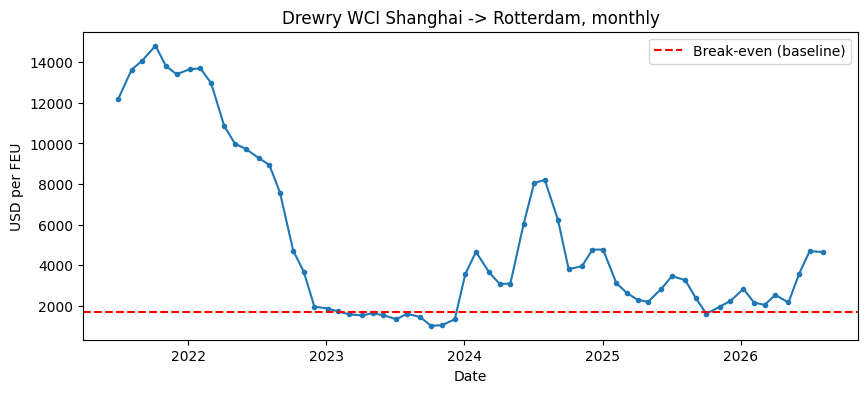

In [7]:
breakeven_freight_rate = 1703  # USD/FEU, baseline break-even from 10_monte_carlo (total cost / loaded FEU)

plt.figure(figsize=(10, 4))
plt.plot(wci_df["assessment_date"], wci_df["freight_rate"], marker="o", markersize=3)
plt.axhline(breakeven_freight_rate, color="red", linestyle="--", label="Break-even (baseline)")
plt.xlabel("Date")
plt.ylabel("USD per FEU")
plt.title("Drewry WCI Shanghai -> Rotterdam, monthly")
plt.legend()
plt.show()

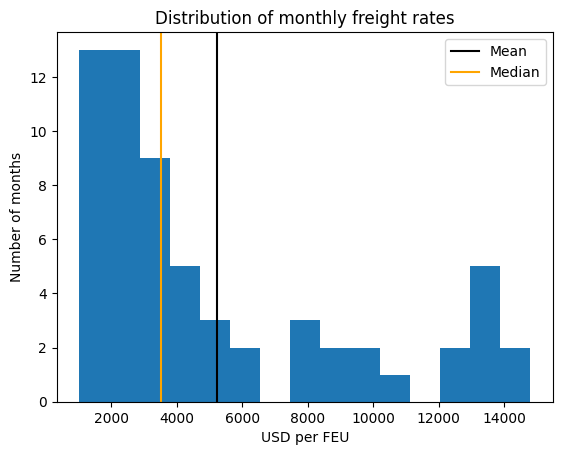

In [8]:
plt.hist(wci_df["freight_rate"], bins=15)
plt.axvline(wci_df["freight_rate"].mean(), color="black", label="Mean")
plt.axvline(wci_df["freight_rate"].median(), color="orange", label="Median")
plt.xlabel("USD per FEU")
plt.ylabel("Number of months")
plt.title("Distribution of monthly freight rates")
plt.legend()
plt.show()

In [9]:
share_boom = (wci_df["freight_rate"] > 9000).mean()
share_below_breakeven = (wci_df["freight_rate"] < breakeven_freight_rate).mean()

print(f'share of months above $9,000:        {share_boom:.1%}')
print(f'share of months below break-even:    {share_below_breakeven:.1%}')

share of months above $9,000:        21.0%
share of months below break-even:    17.7%


## Findings

- 62 months: 49 read directly, 7 derived exactly, 6 approximated (deviation under 1% where verified against exact values).
- Strongly right-skewed: median \$3,523, mean \$5,216, range \$1,027 – \$14,807. A normal distribution would be a poor fit, which is one reason the model uses bootstrap.
- The sample covers several distinct regimes: COVID peak (2021–22), crash (2022), trough (2023), Red Sea crisis (2024) and normalisation (2025–26).
- 21% of months lie above \$9,000, almost all from the COVID period. 18% lie below baseline break-even.
- The \$9,000 threshold is descriptive only. The post-COVID scenario in the Monte Carlo model is defined by events (from Sep 2022), not by rate level, to avoid selecting data on the outcome.

## Save processed data

Only the columns needed by the model are kept. Source URLs and notes remain in the raw file. The output is uploaded to `data/processed/`.

In [10]:
wci_processed = wci_df[["month", "assessment_date", "freight_rate"]]

wci_processed.to_csv("wci_shanghai_rotterdam_processed.csv", index=False)
wci_processed.head()

,month,assessment_date,freight_rate
0,2021-07,2021-07-01,12203
1,2021-08,2021-08-05,13628
2,2021-09,2021-09-02,14074
3,2021-10,2021-10-07,14807
4,2021-11,2021-11-04,13801
